## Loading imports and data

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from scipy.special import gammaln, digamma
from scipy.optimize import basinhopping, minimize
from FPCA import FPCA, Phimaker, omegacomputer, penaltymatrixmaker


In [8]:
def partmissing(sensorseries):
    mask = ~np.isnan(sensorseries)
    if not mask.any(): return 100
    start_idx = np.argmax(mask)
    end_idx = len(sensorseries) - np.argmax(mask[::-1]) - 1
    series = sensorseries[start_idx:end_idx+1]
    return np.isnan(series).sum()/len(series) * 100

def partoutlier(sensorseries):
    mask = ~np.isnan(sensorseries)
    if not mask.any(): return None
    start_idx = np.argmax(mask)
    end_idx = len(sensorseries) - np.argmax(mask[::-1]) - 1
    series = sensorseries[start_idx:end_idx+1]

    nonmissing = np.sum(~np.isnan(series))
    outlier_count = np.sum(series > 500)
    return outlier_count / nonmissing * 100

def get_start_percentage(sensorseries):
    mask = ~np.isnan(sensorseries)
    start_idx = np.argmax(mask)
    return (start_idx / len(sensorseries)) * 100

def longest_high_run(sensorseries, threshold=500):
    mask = ~np.isnan(sensorseries)
    if not mask.any(): return None
    start_idx = np.argmax(mask)
    end_idx = len(sensorseries) - np.argmax(mask[::-1]) - 1
    series = sensorseries[start_idx:end_idx+1]

    high = series > threshold

    max_run = 0
    current = 0
    for x in high:
        if x:
            current += 1
            max_run = max(max_run, current)
        else:
            current = 0
    return max_run

def dataloader():
    raw_pollution = pd.read_csv("../../../purpleair/purpleair_download/europe_pm25_wide_WHOLE.csv", index_col=0)
    sensors = pd.read_csv("../../../purpleair/purpleair_download/europe_selected_sensors.csv", index_col=0)
    
    # Step 1: throw away completely useless sensors
    # Keep only viable sensors
    missing_rates = raw_pollution.apply(partmissing, axis=1)
    sensors['missing_rate'] = sensors.index.map(missing_rates)
    sensors = sensors[sensors['missing_rate'] < 50]
    raw_pollution = raw_pollution.loc[sensors.index]

    # Removing extreme outlier cases
    outlier_rates = raw_pollution.apply(partoutlier, axis=1)
    sensors['outlier_rate'] = sensors.index.map(outlier_rates)
    sensors = sensors[sensors['outlier_rate'] < 25]
    raw_pollution = raw_pollution.loc[sensors.index]

    # Removing consistent outlier sensors
    runs = raw_pollution.apply(longest_high_run, axis=1)
    sensors["max_high_run"] = sensors.index.map(runs)
    sensors = sensors[sensors.max_high_run < 14]
    raw_pollution = raw_pollution.loc[sensors.index]

    # Step 2: retrieving data that is viable for evaluating, but not usefull for training
    start_percentages = raw_pollution.apply(get_start_percentage, axis=1)
    sensors['start_at_percentage'] = raw_pollution.index.map(start_percentages)
    sensors_extra = sensors[sensors['start_at_percentage'] >= 50]
    sensors = sensors[sensors['start_at_percentage'] < 50]
    pollution_extra = raw_pollution.loc[sensors_extra.index]
    pollution = raw_pollution.loc[sensors.index]

    # Step 3: collecting all data
    dates = pd.to_datetime(raw_pollution.columns)
    longitude_extra = sensors_extra["longitude"].values
    latitude_extra = sensors_extra["latitude"].values
    pollution_extra = pollution_extra.values.T
    longitude = sensors["longitude"].values
    latitude = sensors['latitude'].values
    pollution = pollution.values.T
    pollution[pollution == 0] = np.nan

    return dates, longitude, latitude, pollution, longitude_extra, latitude_extra, pollution_extra

## Model specification

In [ ]:
# ----------------------------------------------------------------------------
# Precomputation: everything that depends on the missingness pattern only
# ----------------------------------------------------------------------------

def precompute(Y_list, Phi, R, l=1e-2):
    K = Phi.shape[1]
    cache = []

    for y in Y_list:
        mask = ~np.isnan(y)
        idx = np.flatnonzero(mask)

        if idx.size == 0:
            cache.append(None)
            continue

        Phi_obs = Phi[idx]
        Phi_crossprod = Phi_obs.T @ Phi_obs

        if K == 49:
            regularized_crossprod = Phi_crossprod + l * R
        else:
            regularized_crossprod = Phi_crossprod

        cache.append({
            "idx": idx,
            "y": y[idx],
            "N": idx.size,
            "M": np.linalg.solve(regularized_crossprod, Phi_crossprod),
        })

    return cache

# ----------------------------------------------------------------------------
# Score, scaled score and their Jacobians
# ----------------------------------------------------------------------------

def score_pieces(e, Phi_obs, nu, sigma, N, R, l=1e-2):
    """
    Raw score (for the likelihood gradient) and Fisher-scaled score (for the
    GAS recursion), plus the shared intermediates.
    """
    ee = e.T @ e
    denom = nu * sigma**2 + ee
    g = Phi_obs.T @ e

    raw_scale_factor = (nu + N) / denom
    raw_score = raw_scale_factor * g                                   # d log p / d gamma

    scale_factor = (nu + N + 2) * sigma ** 2 / denom
    gls_step = (
        np.linalg.solve(Phi_obs.T @ Phi_obs + l * R, g)
        if Phi_obs.shape[1] == 49
        else np.linalg.solve(Phi_obs.T @ Phi_obs, g)
    )

    scaled_score = scale_factor * gls_step                                     # scaled score

    return raw_score, scaled_score, g, gls_step, scale_factor, ee, denom


def jacobian_scaled_gamma(g, gls_step, scale_factor, denom, M):
    """Derivative of the scaled score with respect to gamma."""
    return(
        -scale_factor * M 
        + (2 * scale_factor / denom)
        * np.outer(gls_step, g)
    )

def jacobian_scaled_scaling(gls_step, scale_factor, nu, sigma, N, ee, denom):
    """
    Derivatives of the scaled score with respect to sigma and nu.
    The GLS step does not depend on either parameter.
    """
    dscale_dsigma = (nu + N + 2) * 2 * sigma * ee / denom ** 2
    dscale_dnu = sigma**2 * (denom - (nu + N + 2) * sigma ** 2) / denom ** 2
    return dscale_dsigma * gls_step, dscale_dnu * gls_step

def ll(e, N, nu, sigma):
    """Average Student-t log-likelihood per observed location."""
    part1 = (
        gammaln((nu + N) / 2)
        - gammaln(nu / 2)
        - N/2 * np.log(nu * np.pi)
        - N * np.log(sigma)
    )
    part2 = (
        -(nu + N) / 2
        * np.log(1 + (e.T @ e) / (nu * sigma ** 2))
    )
    return (part1 + part2) / N


# ----------------------------------------------------------------------------
# Objective
# ----------------------------------------------------------------------------

G_CAP = 1e10         
PENALTY_LEVEL = 1e3   
PENALTY_CURV = 1e2  


def objective(theta, cache, gamma0, K, R):
    omega = theta[0:K]
    a = theta[K:2 * K]
    b = theta[2 * K:3 * K]
    nu = theta[3 * K]
    sigma = theta[3 * K + 1]

    n_theta = len(theta)
    G = np.zeros((K, n_theta))
    grad = np.zeros(n_theta)
    gamma = gamma0.copy()
    tll = 0.0
    T_eff = 0

    for pre in cache:
        if pre is None:
            gamma = omega + b * gamma
            G[:, 0:K] = np.eye(K) + b[:, None] * G[:, 0:K]
            G[:, 2 * K:3 * K] = np.diag(gamma) + b[:, None] * G[:, 2 * K:3 * K]
            G[:, K:2 * K] *= b[:, None]
            G[:, 3 * K] *= b
            G[:, 3 * K + 1] *= b
            continue

        idx, N, M = pre["idx"], pre["N"], pre["M"]
        Phi_obs = PHI_REF[idx]
        e = pre["y"] - Phi_obs @ gamma
        T_eff += 1

        tll += ll(e, N, nu, sigma)

        raw, s, g, u, k, ee, denom = score_pieces(e, Phi_obs, nu, sigma, N, R)

        # likelihood gradient: chain rule through gamma uses the RAW score
        grad += (raw / N) @ G

        # direct partials wrt sigma and nu
        grad[3 * K + 1] += -1 / sigma + (nu + N) / N * ee / (sigma * denom)

        term1 = 0.5 / N * (digamma((nu + N) / 2) - digamma(nu / 2))
        term2 = -1 / (2 * nu)
        term3 = -0.5 / N * np.log(1 + ee / (nu * sigma ** 2))
        term4 = ((nu + N) / (2 * N)) * (ee / (nu ** 2 * sigma ** 2 + nu * ee))
        grad[3 * K] += term1 + term2 + term3 + term4

        # filter derivative recursion, now driven by the SCALED score
        J_gamma = jacobian_scaled_gamma(g, u, k, denom, M)
        J_sigma, J_nu = jacobian_scaled_scaling(u, k, nu, sigma, N, ee, denom)

        G_new = np.empty_like(G)
        G_new[:, 0:K] = np.eye(K) + b[:, None] * G[:, 0:K]
        G_new[:, K:2 * K] = np.diag(s) + b[:, None] * G[:, K:2 * K]
        G_new[:, 2 * K:3 * K] = np.diag(gamma) + b[:, None] * G[:, 2 * K:3 * K]
        G_new[:, 3 * K] = b * G[:, 3 * K] + a * J_nu
        G_new[:, 3 * K + 1] = b * G[:, 3 * K + 1] + a * J_sigma
        G_new += a[:, None] * (J_gamma @ G)
        G = G_new

        gamma = omega + b * gamma + a * s

        if not np.isfinite(G).all() or np.max(np.abs(G)) > G_CAP:
            # Filter is not invertible here. Return a smooth local surrogate
            # whose gradient points back towards smaller `a`, so L-BFGS-B
            # retreats instead of choking on a 1e93 gradient.
            f = PENALTY_LEVEL + 0.5 * PENALTY_CURV * (a @ a)
            gpen = np.zeros(n_theta)
            gpen[K:2 * K] = PENALTY_CURV * a
            return f, gpen

    if T_eff == 0:
        return PENALTY_LEVEL, np.zeros(n_theta)

    return -tll / T_eff, -grad / T_eff


# ----------------------------------------------------------------------------
# Initial values, bounds, and a bound-aware basinhopping step
# ----------------------------------------------------------------------------

def paraminitmaker(K):
    """
        The same initialisation and bounds are used for any basis dimension K.
    """
    omega0 = np.zeros(K)
    a0 = 0.05 * np.ones(K)
    b0 = 0.90 * np.ones(K)
    nu0 = 12.0
    sigma0 = 0.5
    theta0 = np.concatenate([omega0, a0, b0, [nu0], [sigma0]])

    bounds = (
        [(-1.0, 1.0)] * K        # omega
        + [(1e-4, 0.90)] * K     # a
        + [(1e-3, 0.995)] * K    # b
        + [(2.1, 50.0)]          # nu
        + [(0.05, 5.0)]          # sigma
    )
    return theta0, bounds


class BoundedStep:
    """
    Per-parameter random displacement, scaled to each coordinate's range.

    Scipy's default take_step adds a uniform displacement of the same size
    to every coordinate. When A lives in a narrow interval, this can pin it
    to its upper bound on essentially every hop. Scaling by the bound width
    avoids this, while clipping keeps every hop feasible.
    """

    def __init__(self, bounds, stepsize=0.25, seed=2):
        b = np.asarray(bounds, dtype=float)
        self.lo, self.hi = b[:, 0], b[:, 1]
        self.span = self.hi - self.lo
        self.stepsize = stepsize          # basinhopping tunes this attribute
        self.rng = np.random.default_rng(seed)

    def __call__(self, x):
        step = self.rng.uniform(-1.0, 1.0, size=x.shape) * self.stepsize * self.span
        return np.clip(x + step, self.lo, self.hi)


# ----------------------------------------------------------------------------
# Estimation
# ----------------------------------------------------------------------------

def pooledgammaest(Y_list, Phi, R, l=0.1):
    K = Phi.shape[1]
    ystar, Phistar = [], []
    for y in Y_list:
        mask = ~np.isnan(y)
        ystar.append(y[mask])
        Phistar.append(Phi[mask])
    ystar = np.concatenate(ystar)
    Phistar = np.concatenate(Phistar)
    if K == 49:
        return np.linalg.solve(Phistar.T @ Phistar + l * R, Phistar.T @ ystar)
    else:
        return np.linalg.lstsq(Phistar, ystar, rcond=None)[0]


PHI_REF = None 


def paramest(Y_list_train, Phi, R, l=1e-2, niter=50, seed=2, verbose=True):
    global PHI_REF
    PHI_REF = Phi

    K = Phi.shape[1]
    theta0, bounds = paraminitmaker(K)
    gamma0 = pooledgammaest(Y_list_train, Phi, R)
    cache = precompute(Y_list_train, Phi, R, l=l)

    def obj(theta):
        return objective(theta, cache, gamma0, K, R)

    # sanity check at the starting point
    f0, g0 = obj(theta0)
    if verbose:
        print(f"objective at theta0: {f0:.6f}   |grad| = {np.linalg.norm(g0):.3e}")
        if f0 >= PENALTY_LEVEL:
            print("WARNING: filter already unstable at theta0 -- lower a0.")

    minimizer_kwargs = {
        "method": "L-BFGS-B",
        "jac": True,
        "bounds": bounds,
        "options": {"maxiter": 10**5},
    }

    result = basinhopping(
        obj,
        theta0,
        minimizer_kwargs=minimizer_kwargs,
        take_step=BoundedStep(bounds, stepsize=0.25, seed=seed),
        niter=niter,
        disp=verbose,
        seed=seed,
    )

    theta = result.x
    omega_est = theta[0:K]
    a_est = theta[K:2 * K]
    b_est = theta[2 * K:3 * K]
    nu_est = theta[3 * K]
    sigma_est = theta[3 * K + 1]

    if verbose:
        print("a     :", np.round(a_est, 4))
        print("b     :", np.round(b_est, 4))
        print("nu    :", nu_est)
        print("sigma :", sigma_est)
        print("final objective:", result.fun)

    return omega_est, a_est, b_est, nu_est, sigma_est


# ----------------------------------------------------------------------------
# Filtering / forecasting
# ----------------------------------------------------------------------------

def gammaupdater(gamma, omega, b, a, nu, sigma, y, Phi, R, l=1e-2):
    mask = ~np.isnan(y)

    if not np.any(mask):
        return omega + b * gamma

    y_obs = y[mask]
    Phi_obs = Phi[mask]
    N = Phi_obs.shape[0]
    K = Phi_obs.shape[1]

    e = y_obs - Phi_obs @ gamma

    Phi_crossprod = Phi_obs.T @ Phi_obs

    if K == 49:
        regularized_crossprod = Phi_crossprod + l * R
    else:
        regularized_crossprod = Phi_crossprod

    denom = nu * sigma**2 + e @ e
    scale_factor = (nu + N + 2) * sigma**2 / denom
    scaled_score = scale_factor * np.linalg.solve(regularized_crossprod, Phi_obs.T @ e)

    return omega + b * gamma + a * scaled_score


def onestepforecaster(Y_list_test, Phi, Phi_surface, omega_est, a_est, b_est, nu_est, sigma_est, gammatilde, R):
    Mutilde_list_test = []
    Mutilde_list_surface_test = []
    for y in Y_list_test:
        mutilde = Phi @ gammatilde
        mutilde_surface = Phi_surface @ gammatilde
        Mutilde_list_test.append(mutilde)
        Mutilde_list_surface_test.append(mutilde_surface)
        gammatilde = gammaupdater(gammatilde, omega_est, b_est, a_est, nu_est, sigma_est, y, Phi, R)

    return np.array(Mutilde_list_test), np.array(Mutilde_list_surface_test)

def insampleforecaster(Y_list_train, Phi, Phi_surface, omega_est, a_est, b_est, nu_est, sigma_est, gammatilde, R):
    Mutilde_list_train = []
    Mutilde_list_surface_train = []

    for y in Y_list_train:
        mutilde = Phi @ gammatilde
        mutilde_surface = Phi_surface @ gammatilde

        Mutilde_list_train.append(mutilde)
        Mutilde_list_surface_train.append(mutilde_surface)

        gammatilde = gammaupdater(gammatilde, omega_est, b_est, a_est, nu_est, sigma_est, y, Phi, R)

    return (
        np.array(Mutilde_list_train),
        np.array(Mutilde_list_surface_train),
        gammatilde
    )

## Performing FPCA

In [10]:
def rescaler(x, eps = 0.01): return eps + (1 - 2*eps) * (x - np.min(x)) / (np.max(x) - np.min(x))

In [11]:
dates, longitude, latitude, pollution, _, _, _ = dataloader()
eval_indices = np.arange(len(longitude)-75, len(longitude))
train_indices = np.arange(len(longitude)-75)
s1 = rescaler(longitude[train_indices])
s2 = rescaler(latitude[train_indices])
s1_eval = rescaler(longitude[eval_indices])
s2_eval = rescaler(latitude[eval_indices])
Phi = Phimaker(s1, s2)
Phi_surface = Phimaker(s1_eval, s2_eval)

Omega0, Omega1, Omega2 = omegacomputer()
R = penaltymatrixmaker(Omega0, Omega1, Omega2)

Y_list_surface = np.log(pollution[:, eval_indices])
Y_list = np.log(pollution[:, train_indices])
Y_list_train = Y_list[:-365]
Y_list_test = Y_list[-365:]


T, N = Y_list.shape
r = 7
_, Phi_eig, Phi_surface_eig, Level, Level_eval = FPCA(Y_list_train, Phi, Phi_surface, r)
Level_list = np.tile(Level, (T,1))
Level_list_eval = np.tile(Level_eval, (T,1))
Y_list = Y_list - Level_list
Y_list_surface = Y_list_surface - Level_list_eval
Y_list_train = Y_list[:-365]
Y_list_test = Y_list[-365:]
Y_list_surface_test = Y_list_surface[-365:]

## Model Fit: dimension reduction

In [12]:
omega_est, a_est, b_est, nu_est, sigma_est = paramest(Y_list_train, Phi_eig, R)
gammahat = pooledgammaest(Y_list_train, Phi_eig, R)
Mutilde_list_train, Mutilde_list_surface_train, gammahat0 = insampleforecaster(Y_list_train, Phi_eig, Phi_surface_eig, omega_est, a_est, b_est, nu_est, sigma_est, gammahat, R)
Mutilde_list_test, Mutilde_list_surface_test = onestepforecaster(Y_list_test, Phi_eig, Phi_surface_eig, omega_est, a_est, b_est, nu_est, sigma_est, gammahat0, R)


Mutilde_list = np.concatenate((Mutilde_list_train, Mutilde_list_test)) + Level_list
Mutilde_list_surface = np.concatenate((Mutilde_list_surface_train, Mutilde_list_surface_test)) + Level_list_eval
Mutilde_list_complete_fpca = np.exp(np.hstack((Mutilde_list, Mutilde_list_surface)))

errors = np.abs(
    np.exp(Mutilde_list_test + Level_list[-365:])
    - np.exp(Y_list_test + Level_list[-365:])
)
daily_mae = np.nanmean(errors, axis=1)
MAE = np.mean(daily_mae)

errors_surface = np.abs(
    np.exp(Mutilde_list_surface_test + Level_list_eval[-365:])
    - np.exp(Y_list_surface_test + Level_list_eval[-365:])
)
daily_mae_surface = np.nanmean(errors_surface, axis=1)
MAE_surface = np.mean(daily_mae_surface)


print(f"Out of sample MAE of used sensors: {MAE}")
print(f"Out of sample MAE of unused sensors: {MAE_surface}")

objective at theta0: 1.323091   |grad| = 8.460e-01
basinhopping step 0: f 1.12051
basinhopping step 1: f 1.12051 trial_f 1.12051 accepted True lowest_f 1.12051
basinhopping step 2: f 1.12051 trial_f 1.12051 accepted True lowest_f 1.12051
found new global minimum on step 2 with function value 1.12051
a     : [0.9    0.832  0.7993 0.8268 0.5618 0.6636 0.6424]
b     : [0.8663 0.688  0.6281 0.8652 0.5415 0.4952 0.5887]
nu    : 24.803243462088435
sigma : 0.7556991395785914
final objective: 1.1205102029705265
Out of sample MAE of used sensors: 8.271323230546061
Out of sample MAE of unused sensors: 13.304526968169919


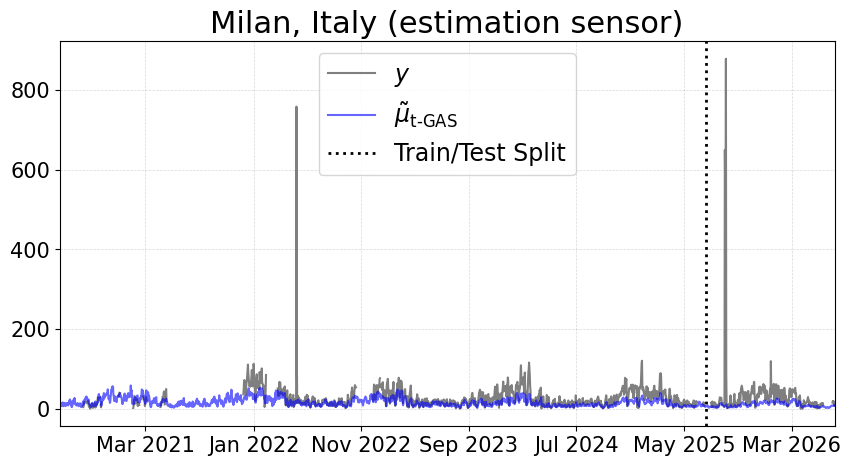

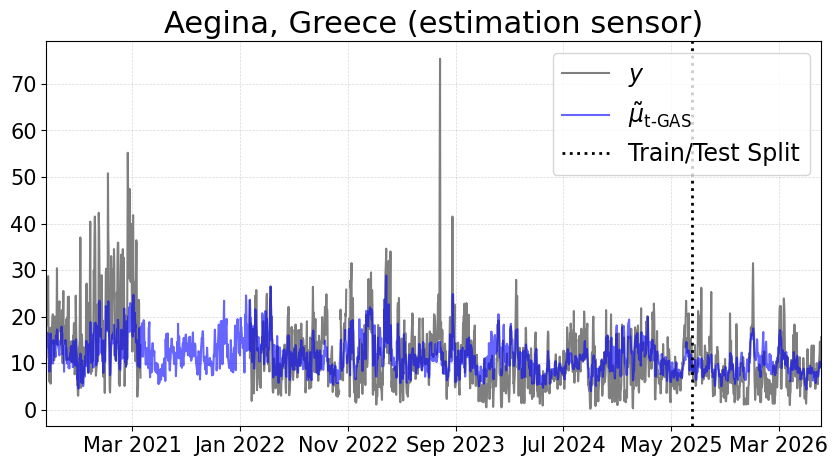

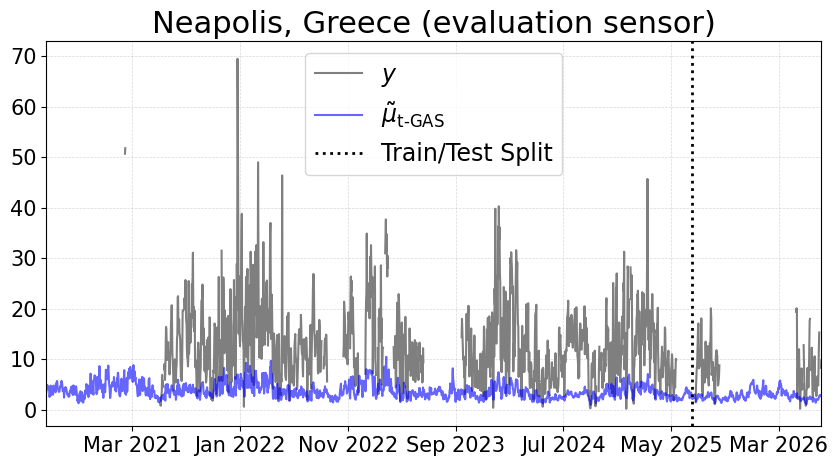

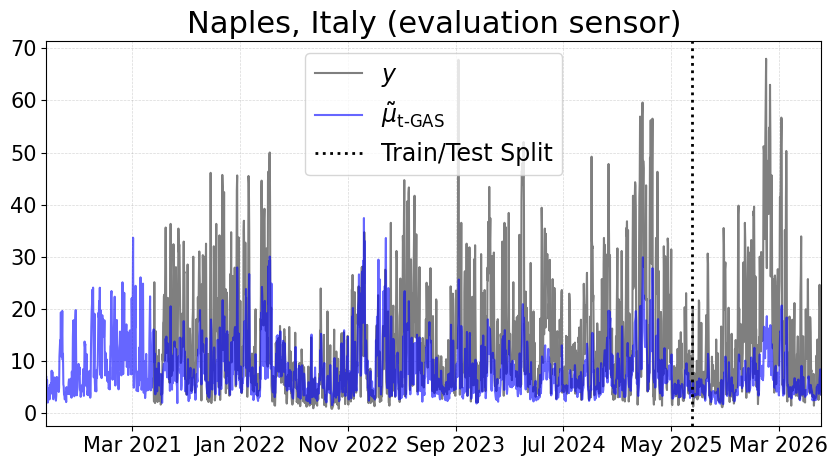

In [13]:
plot_dict = {
    21 : "Milan, Italy (estimation sensor)", 
    62 : "Aegina, Greece (estimation sensor)", 
    135 : "Neapolis, Greece (evaluation sensor)", 
    145 : "Naples, Italy (evaluation sensor)"}


for idx in plot_dict.keys():
    plt.figure(figsize=(10, 5))
    plt.plot(dates, pollution[:, idx], label=r"$y$", color='#7f7f7f')
    plt.plot(dates, Mutilde_list_complete_fpca[:, idx], label=r"$\tilde{\mu}_{\text{t-GAS}}$", color='blue', alpha=0.6)
    plt.axvline(x=dates[-365], color='black', linestyle=':', linewidth=2, label="Train/Test Split")
    plt.xlim(dates[0], dates[-1])
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=10))
    plt.legend(fontsize=17)
    plt.xticks(fontsize=15)
    plt.yticks(fontsize=15)
    plt.grid(color='grey', linestyle='--', linewidth=0.5, alpha=0.3)
    plt.title(f"{plot_dict[idx]}", fontsize=22)
    plt.show()

## Model Fit: no dimension reduction

In [14]:
omega_est, a_est, b_est, nu_est, sigma_est = paramest(Y_list_train, Phi, R)
gammahat = pooledgammaest(Y_list_train, Phi, R)
Mutilde_list_train, Mutilde_list_surface_train, gammahat0 = insampleforecaster(Y_list_train, Phi, Phi_surface, omega_est, a_est, b_est, nu_est, sigma_est, gammahat, R)
Mutilde_list_test, Mutilde_list_surface_test = onestepforecaster(Y_list_test, Phi, Phi_surface, omega_est, a_est, b_est, nu_est, sigma_est, gammahat0, R)


Mutilde_list = np.concatenate((Mutilde_list_train, Mutilde_list_test)) + Level_list
Mutilde_list_surface = np.concatenate((Mutilde_list_surface_train, Mutilde_list_surface_test)) + Level_list_eval
Mutilde_list_complete_bspline = np.exp(np.hstack((Mutilde_list, Mutilde_list_surface)))

errors = np.abs(
    np.exp(Mutilde_list_test + Level_list[-365:])
    - np.exp(Y_list_test + Level_list[-365:])
)
daily_mae = np.nanmean(errors, axis=1)
MAE = np.mean(daily_mae)

errors_surface = np.abs(
    np.exp(Mutilde_list_surface_test + Level_list_eval[-365:])
    - np.exp(Y_list_surface_test + Level_list_eval[-365:])
)
daily_mae_surface = np.nanmean(errors_surface, axis=1)
MAE_surface = np.mean(daily_mae_surface)


print(f"Out of sample MAE of used sensors: {MAE}")
print(f"Out of sample MAE of unused sensors: {MAE_surface}")

objective at theta0: 1.322278   |grad| = 3.200e-01


KeyboardInterrupt: 

In [ ]:
plot_dict = {
    21 : "Milan, Italy (estimation sensor)", 
    62 : "Aegina, Greece (estimation sensor)", 
    135 : "Neapolis, Greece (evaluation sensor)", 
    145 : "Naples, Italy (evaluation sensor)"}


for idx in plot_dict.keys():
    plt.figure(figsize=(10, 5))
    plt.plot(dates, pollution[:, idx], label=r"$y$", color='#7f7f7f')
    plt.plot(dates, Mutilde_list_complete_bspline[:, idx], label=r"$\tilde{\mu}_{\text{fGAS}, \text{B-spline}}$", color='blue', alpha=0.6)
    plt.plot(dates, Mutilde_list_complete_fpca[:, idx], label=r"$\tilde{\mu}_{\text{fGAS}, \text{FPCA}}$", color='red', alpha=0.6)
    plt.axvline(x=dates[-365], color='black', linestyle=':', linewidth=2, label="Train/Test Split")
    plt.xlim(dates[0], dates[-1])
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=10))
    plt.legend(fontsize=17)
    plt.xticks(fontsize=15)
    plt.yticks(fontsize=15)
    plt.grid(color='grey', linestyle='--', linewidth=0.5, alpha=0.3)
    plt.title(f"{plot_dict[idx]}", fontsize=22)
    plt.show()